# NHL: предсказать успешность команды в следующем сезоне

**Тестовое задание • 100 баллов**

Вы аналитик, которому после окончания сезона нужно оценить перспективы команды
на следующий год. Соберите таблицу с учебного сайта
[Scrape This Site - Hockey Teams](https://www.scrapethissite.com/pages/forms/),
изучите данные и постройте модель классификации.
В работе оцениваются корректность исследования и обоснованность решений.

Ориентир времени: 6-10 часов (знание хоккея не требуется).
Можно обращаться к документации и пользоваться вспомогательными инструментами.
Укажите, чем пользовались; отвечайте за правильность и понимание сданной работы.
Подтверждайте ответы результатами из своего ноутбука.

## Что сдавать

Выполненный IPynb с видимыми результатами и ответами и исходный `data/hockey_raw.csv` разместите на платформе githib.com.
Укажите имя, дату и использованные источники и инструменты в README.

## Что предсказывает модель

Одна строка признаков описывает команду в сезоне `t`.
`target=1`, если доля побед той же команды в сезоне `t+1` строго выше медианной
доли побед всех команд в сезоне `t+1`. В остальных случаях `target=0`.

Медиану считайте по полной исходной таблице будущего года до отбора пар.
В пары включайте одинаковые названия команды с разницей меток сезонов ровно в один год.
Строки без пары исключайте и учитывайте в описании данных.
Будущий `win_rate` и будущая медиана используются для построения target и анализа
готовых прогнозов. Признаки модели должны быть известны после сезона `t`.

## Схема проверки

Делите данные по году целевого сезона:

| Часть | target_year | Назначение |
|---|---|---|
| train | не позднее 2005 | Подготовка данных и обучение |
| validation | 2006-2008 | Сравнение вариантов и выбор решения |
| test | 2009-2011 | Одна итоговая оценка выбранного решения |

Основная метрика: ROC-AUC по вероятности класса 1.
На итоговом этапе также используйте F1 и accuracy при пороге 0.5.
Финальный test используйте после выбора решения на validation.

## Как оценивается работа

| Область | Баллы |
|---|---:|
| Сбор и понимание данных | 15 |
| Построение задачи и корректность проверки | 20 |
| Исследовательский анализ | 20 |
| Модели и эксперименты | 25 |
| Итоговая оценка и анализ ошибок | 15 |
| Ясность и воспроизводимость | 5 |
| **Всего** | **100** |

Ниже перечислены обязательные этапы работы. Внутри них вы самостоятельно выбираете
исследовательские вопросы, графики, признаки, обработку данных, эксперимент и способ
разбора ошибок. Оценивается качество решений, а не совпадение с эталонным маршрутом.
Сложность метода сама по себе не даёт преимущества. Корректный эксперимент может
получить полный балл и в случае отсутствия улучшения.

## Требования к сбору

Итоговая исходная таблица должна иметь столбцы `team`, `year`, `wins`, `losses`,
`ot_losses`, `win_rate`, `goals_for`, `goals_against`, `goal_diff`.
Самостоятельно исследуйте страницу и определите способ получения всей таблицы.

**Автор:** Сахаров Никита Александрович\
**Дата:** 13.10.2026\
**Использованные источники и инструменты:**\
https://en.wikipedia.org/wiki/Overtime_(ice_hockey) \
https://en.wikipedia.org/wiki/2004%E2%80%9305_NHL_lockout

pandas\
numpy\
requests\
matplotlib\
scikit-learn: Pipeline, SimpleImputer, StandardScaler, LogisticRegression, \
DummyClassifier, ROC-AUC, F1 и accuracy

Подключаю библиотеки: pandas и numpy для работы с таблицами, requests для запросов к сайту, StringIO для чтения HTML, os и time для папки и паузы между запросами, matplotlib для графиков, scikit-learn для моделей и метрик.

In [1]:
import pandas as pd
import os, time
from io import StringIO
import requests
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score, f1_score, accuracy_score

## Раздел 1. Сбор и понимание данных: 15 баллов

### 1.1. Соберите и сохраните данные

Соберите все страницы сайта в одну таблицу с указанными девятью столбцами.
Сохраните исходную выгрузку в `data/hockey_raw.csv`. Укажите URL и дату сбора,
число обработанных страниц и число строк. Покажите, как проверили,
что сбор не ограничился первой страницей и при повторном анализе можно читать CSV.

Адрес страницы с таблицей и заголовок запроса.

In [2]:
url = "https://www.scrapethissite.com/pages/forms"
headers = {"User-Agent": "Mozila/5.0"}

Загружаю страницы по 100 строк, пока сайт не вернёт пустую таблицу, и собираю их в один датафрейм

In [3]:
frames = []
for page in range(1, 51):
  resp = requests.get(url, params={"page_num": page, "per_page": 100}, headers=headers)
  resp.raise_for_status()
  hockey_df_page = pd.read_html(StringIO(resp.text))[0]
  if hockey_df_page.empty:
    break
  frames.append(hockey_df_page)
  time.sleep(0.5)
hockey_df = pd.concat(frames, ignore_index=True)

Переименовываю столбцы

In [4]:
hockey_df.columns = ["team", "year", "wins", "losses", "ot_losses", "win_rate", "goals_for", "goals_against", "goal_diff"]

Начало таблицы

In [5]:
hockey_df.head(10)

,team,year,wins,losses,ot_losses,win_rate,goals_for,goals_against,goal_diff
0,Boston Bruins,1990,44,24,NaN,0.550,299,264,35
1,Buffalo Sabres,1990,31,30,NaN,0.388,292,278,14
2,Calgary Flames,1990,46,26,NaN,0.575,344,263,81
3,Chicago Blackhawks,1990,49,23,NaN,0.613,284,211,73
4,Detroit Red Wings,1990,34,38,NaN,0.425,273,298,-25
5,Edmonton Oilers,1990,37,37,NaN,0.463,272,272,0
6,Hartford Whalers,1990,31,38,NaN,0.388,238,276,-38
7,Los Angeles Kings,1990,46,24,NaN,0.575,340,254,86
8,Minnesota North Stars,1990,27,39,NaN,0.338,256,266,-10
9,Montreal Canadiens,1990,39,30,NaN,0.487,273,249,24


Конец таблицы

In [6]:
hockey_df.tail(10)

,team,year,wins,losses,ot_losses,win_rate,goals_for,goals_against,goal_diff
572,Philadelphia Flyers,2011,47,26,9.0,0.573,264,232,32
573,Phoenix Coyotes,2011,42,27,13.0,0.512,216,204,12
574,Pittsburgh Penguins,2011,51,25,6.0,0.622,282,221,61
575,San Jose Sharks,2011,43,29,10.0,0.524,228,210,18
576,St. Louis Blues,2011,49,22,11.0,0.598,210,165,45
577,Tampa Bay Lightning,2011,38,36,8.0,0.463,235,281,-46
578,Toronto Maple Leafs,2011,35,37,10.0,0.427,231,264,-33
579,Vancouver Canucks,2011,51,22,9.0,0.622,249,198,51
580,Washington Capitals,2011,42,32,8.0,0.512,222,230,-8
581,Winnipeg Jets,2011,37,35,10.0,0.451,225,246,-21


Число страниц с данными и общее число строк.

In [7]:
pages_count = len(frames)
rows_count = hockey_df.shape[0]
pages_count, rows_count

(6, 582)

Число строк на каждой загруженной странице.

In [8]:
[len(i) for i in frames]

[100, 100, 100, 100, 100, 82]

Сохраняю исходную выгрузку в `data/hockey_raw.csv`.

In [9]:
os.makedirs("data", exist_ok=True)
hockey_df.to_csv("data/hockey_raw.csv", index=False, encoding="utf-8-sig")

Читаю таблицу из CSV заново, дальше работа идёт с прочитанным файлом.

In [10]:
hockey_df = pd.read_csv("data/hockey_raw.csv", encoding="utf-8-sig")
hockey_df.head(10)

,team,year,wins,losses,ot_losses,win_rate,goals_for,goals_against,goal_diff
0,Boston Bruins,1990,44,24,NaN,0.550,299,264,35
1,Buffalo Sabres,1990,31,30,NaN,0.388,292,278,14
2,Calgary Flames,1990,46,26,NaN,0.575,344,263,81
3,Chicago Blackhawks,1990,49,23,NaN,0.613,284,211,73
4,Detroit Red Wings,1990,34,38,NaN,0.425,273,298,-25
5,Edmonton Oilers,1990,37,37,NaN,0.463,272,272,0
6,Hartford Whalers,1990,31,38,NaN,0.388,238,276,-38
7,Los Angeles Kings,1990,46,24,NaN,0.575,340,254,86
8,Minnesota North Stars,1990,27,39,NaN,0.338,256,266,-10
9,Montreal Canadiens,1990,39,30,NaN,0.487,273,249,24


**Ответ 1.1:**

Собрал все страницы сайта https://www.scrapethissite.com/pages/forms/ в одну таблицу hockey_df. Для отправки запроса использовалась библиотека requests, для чтения html файла использовалась библиотека pandas и io.StringIO, которая превращает строку в объект, который ведёт себя как открытый файл. Страницы запрашивались по 100 строк (per_page=100), цикл останавливался на первой пустой странице. Всего было отправлено 7 запросов: 6 страниц с данными (100, 100, 100, 100, 100 и 82 строки) и седьмая пустая, на которой сбор остановился. Итоговая таблица содержит 582 строки за 1990-2011 годы. Проверил, что сбор не ограничился первой страницей по числу строк на каждой странице, а также с помощью pd.tail, которая выводит конец датафрейма, и сравнения с содержимым последней страницы сайта. Повторяющихся пар команда-год нет (проверка в 1.2), значит страницы не дублируют друг друга. Таблица сохранена в data/hockey_raw.csv, повторное чтение CSV работает, и дальше вся работа идёт с прочитанным файлом. Выгрузка производилась 12.10.2026 19:50

### 1.2. Проверьте качество таблицы

Изучите типы, пропуски и уникальность пары команда-год.
Добавьте не менее двух проверок согласованности, которые считаете важными
для последующего анализа. Покажите найденные особенности и обоснуйте
решения по их обработке. Сами проверки и способ представления результата выберите самостоятельно.

Типы столбцов и число непустых значений.

In [11]:
hockey_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 582 entries, 0 to 581
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   team           582 non-null    object 
 1   year           582 non-null    int64  
 2   wins           582 non-null    int64  
 3   losses         582 non-null    int64  
 4   ot_losses      358 non-null    float64
 5   win_rate       582 non-null    float64
 6   goals_for      582 non-null    int64  
 7   goals_against  582 non-null    int64  
 8   goal_diff      582 non-null    int64  
dtypes: float64(2), int64(6), object(1)
memory usage: 41.1+ KB


Проверяю, какие типы значений лежат в столбце team с типом object.

In [12]:
hockey_df["team"].map(lambda x: type(x).__name__).value_counts()

,count
team,
str,582


Все значения являются строками, поэтому перевожу team в строковый тип.

In [13]:
hockey_df["team"] = hockey_df["team"].astype("string")

Проверяю, что тип изменился.

In [14]:
hockey_df["team"].info()

<class 'pandas.core.series.Series'>
RangeIndex: 582 entries, 0 to 581
Series name: team
Non-Null Count  Dtype 
--------------  ----- 
582 non-null    string
dtypes: string(1)
memory usage: 4.7 KB


Заменяю пустые строки и текстовые обозначения пропусков на NaN, если они есть.

In [15]:
hockey_df = hockey_df.replace(r'^\s*$', np.nan, regex=True)
hockey_df = hockey_df.replace(['NA', 'N/A', 'null', 'None', '-'], np.nan)

Число пропусков в каждом столбце.

In [16]:
hockey_df.isna().sum()

,0
team,0
year,0
wins,0
losses,0
ot_losses,224
win_rate,0
goals_for,0
goals_against,0
goal_diff,0


Строки с пропуском в ot_losses.

In [17]:
hockey_df[hockey_df["ot_losses"].isna()]

,team,year,wins,losses,ot_losses,win_rate,goals_for,goals_against,goal_diff
0,Boston Bruins,1990,44,24,NaN,0.550,299,264,35
1,Buffalo Sabres,1990,31,30,NaN,0.388,292,278,14
2,Calgary Flames,1990,46,26,NaN,0.575,344,263,81
3,Chicago Blackhawks,1990,49,23,NaN,0.613,284,211,73
4,Detroit Red Wings,1990,34,38,NaN,0.425,273,298,-25
...,...,...,...,...,...,...,...,...,...
219,St. Louis Blues,1998,37,32,NaN,0.451,237,209,28
220,Tampa Bay Lightning,1998,19,54,NaN,0.232,179,292,-113
221,Toronto Maple Leafs,1998,45,30,NaN,0.549,268,231,37
222,Vancouver Canucks,1998,23,47,NaN,0.280,192,258,-66


Строки без пропуска в ot_losses, чтобы сравнить годы.

In [18]:
hockey_df[~hockey_df["ot_losses"].isna()]

,team,year,wins,losses,ot_losses,win_rate,goals_for,goals_against,goal_diff
224,Mighty Ducks of Anaheim,1999,34,33,3.0,0.415,217,227,-10
225,Atlanta Thrashers,1999,14,57,4.0,0.171,170,313,-143
226,Boston Bruins,1999,24,33,6.0,0.293,210,248,-38
227,Buffalo Sabres,1999,35,32,4.0,0.427,213,204,9
228,Calgary Flames,1999,31,36,5.0,0.378,211,256,-45
...,...,...,...,...,...,...,...,...,...
577,Tampa Bay Lightning,2011,38,36,8.0,0.463,235,281,-46
578,Toronto Maple Leafs,2011,35,37,10.0,0.427,231,264,-33
579,Vancouver Canucks,2011,51,22,9.0,0.622,249,198,51
580,Washington Capitals,2011,42,32,8.0,0.512,222,230,-8


Заменяю пропуски в ot_losses на 0.

In [19]:
hockey_df["ot_losses"] = hockey_df["ot_losses"].fillna(0)

Проверяю уникальность пары команда-год.

In [20]:
is_unique = not hockey_df.duplicated(subset=['team', 'year']).any()
is_unique

True

Проверка согласованности: goal_diff должен быть равен goals_for - goals_against.

In [21]:
bad_goal_diff = hockey_df[hockey_df["goals_for"] - hockey_df["goals_against"] != hockey_df["goal_diff"]]
bad_goal_diff

,team,year,wins,losses,ot_losses,win_rate,goals_for,goals_against,goal_diff


Строки, где win_rate не совпадает с wins / (wins + losses + ot_losses) с учётом округления.

In [22]:
bad_win_rate = hockey_df[~np.isclose(hockey_df["wins"] / (hockey_df["wins"] + hockey_df["losses"] + hockey_df["ot_losses"].fillna(0)), hockey_df["win_rate"], rtol=0, atol=0.00051)] #atol = макс ошибка округления до 3 знаков + запас
bad_win_rate

,team,year,wins,losses,ot_losses,win_rate,goals_for,goals_against,goal_diff
0,Boston Bruins,1990,44,24,0.0,0.550,299,264,35
1,Buffalo Sabres,1990,31,30,0.0,0.388,292,278,14
2,Calgary Flames,1990,46,26,0.0,0.575,344,263,81
3,Chicago Blackhawks,1990,49,23,0.0,0.613,284,211,73
4,Detroit Red Wings,1990,34,38,0.0,0.425,273,298,-25
...,...,...,...,...,...,...,...,...,...
367,St. Louis Blues,2003,39,30,2.0,0.476,191,198,-7
368,Tampa Bay Lightning,2003,46,22,6.0,0.561,245,192,53
369,Toronto Maple Leafs,2003,45,24,3.0,0.549,242,204,38
370,Vancouver Canucks,2003,43,24,5.0,0.524,235,194,41


Строки, где win_rate совпадает с этой формулой.

In [23]:
good_win_rate = hockey_df[np.isclose(hockey_df["wins"] / (hockey_df["wins"] + hockey_df["losses"] + hockey_df["ot_losses"]), hockey_df["win_rate"], rtol=0, atol=0.00051)] #atol = макс ошибка округления до 3 знаков + запас
good_win_rate

,team,year,wins,losses,ot_losses,win_rate,goals_for,goals_against,goal_diff
372,Mighty Ducks of Anaheim,2005,43,27,12.0,0.524,254,229,25
373,Atlanta Thrashers,2005,41,33,8.0,0.500,281,275,6
374,Boston Bruins,2005,29,37,16.0,0.354,230,266,-36
375,Buffalo Sabres,2005,52,24,6.0,0.634,281,239,42
376,Calgary Flames,2005,46,25,11.0,0.561,218,200,18
...,...,...,...,...,...,...,...,...,...
577,Tampa Bay Lightning,2011,38,36,8.0,0.463,235,281,-46
578,Toronto Maple Leafs,2011,35,37,10.0,0.427,231,264,-33
579,Vancouver Canucks,2011,51,22,9.0,0.622,249,198,51
580,Washington Capitals,2011,42,32,8.0,0.512,222,230,-8


Число матчей в сезоне (wins / win_rate) и число ничьих по годам.

In [24]:
games = (hockey_df["wins"] / hockey_df["win_rate"]).round()
ties = games - hockey_df["wins"] - hockey_df["losses"] - hockey_df["ot_losses"]
pd.DataFrame({"year": hockey_df["year"], "games": games, "ties": ties}).groupby("year").agg(["min", "max"])

games       ties      
       min   max  min   max
year                       
1990  80.0  80.0  6.0  19.0
1991  80.0  80.0  5.0  15.0
1992  84.0  84.0  2.0  12.0
1993  84.0  84.0  3.0  17.0
1994  48.0  48.0  3.0  12.0
1995  82.0  82.0  4.0  18.0
1996  82.0  82.0  7.0  19.0
1997  82.0  82.0  8.0  18.0
1998  82.0  82.0  5.0  19.0
1999  82.0  82.0  6.0  19.0
2000  82.0  82.0  5.0  17.0
2001  82.0  82.0  4.0  16.0
2002  82.0  82.0  6.0  16.0
2003  82.0  82.0  7.0  20.0
2005  82.0  82.0  0.0   0.0
2006  82.0  82.0  0.0   0.0
2007  82.0  82.0  0.0   0.0
2008  82.0  82.0  0.0   0.0
2009  82.0  82.0  0.0   0.0
2010  82.0  82.0  0.0   0.0
2011  82.0  82.0  0.0   0.0

Число команд в каждом сезоне.

In [25]:
hockey_df.groupby("year").size()

,0
year,
1990,21
1991,22
1992,24
1993,26
1994,26
1995,26
1996,26
1997,26
1998,27


**Ответ 1.2:**

Изучил типы, пропуски и уникальность пары команда-год. Пары команда-год уникальны. Пропуски есть только в столбце ot_losses, которые отражают проигранные матчи в овертайме, причём NaN встречается только до 1999 года, что отражает правила НХЛ, в которых поражения в овертайме были добавлены только в 1999 году. Пропуски заменил на 0: до 1999 года поражение в овертайме записывалось как обычное поражение (в losses), поэтому отдельных поражений в овертайме у команд не было.

В столбце team встречается тип object. При детальном анализе оказалось, что все объекты столбца являются строками, поэтому тип столбца названия команды был заменён на string.

Также были проведены проверки на согласованность. goal_diff корректно рассчитывается как разность забитых и пропущенных голов. Доля побед корректно рассчитывается по формуле wins / (wins + losses + ot_losses) с 2005 года (с того момента, когда ничьи были отменены) с учётом допустимой погрешности. До 2005 года в знаменатель входят ещё и ничьи, которых нет в таблице. Это подтверждается расчётом: wins / win_rate даёт одинаковое число матчей у всех команд в каждом сезоне (80 в 1990-1991, 84 в 1992-1993, 48 в укороченном сезоне 1994 и 82 начиная с 1995), а разница этого числа с wins + losses + ot_losses (ничьи) до 2005 года больше нуля, а начиная с 2005 года равна нулю. Значит win_rate это доля побед от всех сыгранных матчей, и его можно сравнивать между сезонами. При этом в сезоне 1994 было всего 48 матчей, поэтому доля побед в нём менее надёжна.

В таблице нет сезона 2004 (он не проводился из-за локаута), а число команд в сезоне растёт с 21 в 1990 году до 30 начиная с 2000 года. Это важно для построения пар в 2.1: строки 2003 года не получат пару, а новые команды появляются в таблице без предыдущего сезона.

## Раздел 2. Построение задачи и корректность проверки: 20 баллов

### 2.1. Постройте target

Соедините строку команды в сезоне `t` с той же командой ровно в сезоне `t+1`
и постройте target по определению задания. Покажите число полученных пар,
число и годы исключённых строк, а также число случаев равенства будущей медиане.
Проверьте расчёт вручную минимум на двух содержательно разных примерах.

Копия таблицы для следующего сезона, к названиям столбцов добавляю `_next`.

In [26]:
hockey_df_next = hockey_df.copy()
hockey_df_next.columns = [i + "_next" for i in hockey_df.columns]

Уменьшаю год на 1, чтобы строка сезона t+1 совпала по году с сезоном t.

In [27]:
hockey_df_next["year_next"] = hockey_df_next["year_next"] - 1

Проверяю результат.

In [28]:
hockey_df_next.head()

,team_next,year_next,wins_next,losses_next,ot_losses_next,win_rate_next,goals_for_next,goals_against_next,goal_diff_next
0,Boston Bruins,1989,44,24,0.0,0.550,299,264,35
1,Buffalo Sabres,1989,31,30,0.0,0.388,292,278,14
2,Calgary Flames,1989,46,26,0.0,0.575,344,263,81
3,Chicago Blackhawks,1989,49,23,0.0,0.613,284,211,73
4,Detroit Red Wings,1989,34,38,0.0,0.425,273,298,-25


Возвращаю столбцам team и year исходные названия, чтобы объединять по ним.

In [29]:
hockey_df_next = hockey_df_next.rename(columns={'team_next': 'team', 'year_next': 'year'})

Проверяю результат.

In [30]:
hockey_df_next.head()

,team,year,wins_next,losses_next,ot_losses_next,win_rate_next,goals_for_next,goals_against_next,goal_diff_next
0,Boston Bruins,1989,44,24,0.0,0.550,299,264,35
1,Buffalo Sabres,1989,31,30,0.0,0.388,292,278,14
2,Calgary Flames,1989,46,26,0.0,0.575,344,263,81
3,Chicago Blackhawks,1989,49,23,0.0,0.613,284,211,73
4,Detroit Red Wings,1989,34,38,0.0,0.425,273,298,-25


Соединяю сезон t с сезоном t+1 той же команды. Left join оставляет строки без пары, чтобы их можно было посмотреть.

In [31]:
hockey_df_timediff = hockey_df.merge(hockey_df_next, on=["team", "year"], how="left")

Результат объединения.

In [32]:
hockey_df_timediff

,team,year,wins,losses,ot_losses,win_rate,goals_for,goals_against,goal_diff,wins_next,losses_next,ot_losses_next,win_rate_next,goals_for_next,goals_against_next,goal_diff_next
0,Boston Bruins,1990,44,24,0.0,0.550,299,264,35,36.0,32.0,0.0,0.450,270.0,275.0,-5.0
1,Buffalo Sabres,1990,31,30,0.0,0.388,292,278,14,31.0,37.0,0.0,0.388,289.0,299.0,-10.0
2,Calgary Flames,1990,46,26,0.0,0.575,344,263,81,31.0,37.0,0.0,0.388,296.0,305.0,-9.0
3,Chicago Blackhawks,1990,49,23,0.0,0.613,284,211,73,36.0,29.0,0.0,0.450,257.0,236.0,21.0
4,Detroit Red Wings,1990,34,38,0.0,0.425,273,298,-25,43.0,25.0,0.0,0.537,320.0,256.0,64.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
577,Tampa Bay Lightning,2011,38,36,8.0,0.463,235,281,-46,NaN,NaN,NaN,NaN,NaN,NaN,NaN
578,Toronto Maple Leafs,2011,35,37,10.0,0.427,231,264,-33,NaN,NaN,NaN,NaN,NaN,NaN,NaN
579,Vancouver Canucks,2011,51,22,9.0,0.622,249,198,51,NaN,NaN,NaN,NaN,NaN,NaN,NaN
580,Washington Capitals,2011,42,32,8.0,0.512,222,230,-8,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Строки без пары: у них нет данных следующего сезона.

In [33]:
hockey_df_timediff[hockey_df_timediff["win_rate_next"].isna()]

,team,year,wins,losses,ot_losses,win_rate,goals_for,goals_against,goal_diff,wins_next,losses_next,ot_losses_next,win_rate_next,goals_for_next,goals_against_next,goal_diff_next
51,Minnesota North Stars,1992,36,38,0.0,0.429,272,293,-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN
111,Quebec Nordiques,1994,30,13,0.0,0.625,185,134,51,NaN,NaN,NaN,NaN,NaN,NaN,NaN
144,Winnipeg Jets,1995,36,40,0.0,0.439,275,291,-16,NaN,NaN,NaN,NaN,NaN,NaN,NaN
155,Hartford Whalers,1996,32,39,0.0,0.390,226,256,-30,NaN,NaN,NaN,NaN,NaN,NaN,NaN
342,Mighty Ducks of Anaheim,2003,29,35,8.0,0.354,184,213,-29,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
577,Tampa Bay Lightning,2011,38,36,8.0,0.463,235,281,-46,NaN,NaN,NaN,NaN,NaN,NaN,NaN
578,Toronto Maple Leafs,2011,35,37,10.0,0.427,231,264,-33,NaN,NaN,NaN,NaN,NaN,NaN,NaN
579,Vancouver Canucks,2011,51,22,9.0,0.622,249,198,51,NaN,NaN,NaN,NaN,NaN,NaN,NaN
580,Washington Capitals,2011,42,32,8.0,0.512,222,230,-8,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Число строк без пары.

In [34]:
hockey_df_timediff[hockey_df_timediff["win_rate_next"].isna()].count()

,0
team,66
year,66
wins,66
losses,66
ot_losses,66
win_rate,66
goals_for,66
goals_against,66
goal_diff,66
wins_next,0


Годы строк без пары.

In [35]:
hockey_df_timediff[hockey_df_timediff["win_rate_next"].isna()].groupby("year").size()

,0
year,
1992,1
1994,1
1995,1
1996,1
2003,30
2005,1
2010,1
2011,30


Строки без пары, кроме 2003 и 2011 годов: команды, которые переехали или сменили название.

In [36]:
hockey_df_timediff[hockey_df_timediff["win_rate_next"].isna() & ~hockey_df_timediff["year"].isin([2003, 2011])][["team", "year"]]

,team,year
51,Minnesota North Stars,1992
111,Quebec Nordiques,1994
144,Winnipeg Jets,1995
155,Hartford Whalers,1996
372,Mighty Ducks of Anaheim,2005
523,Atlanta Thrashers,2010


Удаляю строки без пары.

In [37]:
hockey_df_timediff = hockey_df_timediff[~hockey_df_timediff["win_rate_next"].isna()].copy()

Таблица пар.

In [38]:
hockey_df_timediff

,team,year,wins,losses,ot_losses,win_rate,goals_for,goals_against,goal_diff,wins_next,losses_next,ot_losses_next,win_rate_next,goals_for_next,goals_against_next,goal_diff_next
0,Boston Bruins,1990,44,24,0.0,0.550,299,264,35,36.0,32.0,0.0,0.450,270.0,275.0,-5.0
1,Buffalo Sabres,1990,31,30,0.0,0.388,292,278,14,31.0,37.0,0.0,0.388,289.0,299.0,-10.0
2,Calgary Flames,1990,46,26,0.0,0.575,344,263,81,31.0,37.0,0.0,0.388,296.0,305.0,-9.0
3,Chicago Blackhawks,1990,49,23,0.0,0.613,284,211,73,36.0,29.0,0.0,0.450,257.0,236.0,21.0
4,Detroit Red Wings,1990,34,38,0.0,0.425,273,298,-25,43.0,25.0,0.0,0.537,320.0,256.0,64.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
547,St. Louis Blues,2010,38,33,11.0,0.463,240,234,6,49.0,22.0,11.0,0.598,210.0,165.0,45.0
548,Tampa Bay Lightning,2010,46,25,11.0,0.561,247,240,7,38.0,36.0,8.0,0.463,235.0,281.0,-46.0
549,Toronto Maple Leafs,2010,37,34,11.0,0.451,218,251,-33,35.0,37.0,10.0,0.427,231.0,264.0,-33.0
550,Vancouver Canucks,2010,54,19,9.0,0.659,262,185,77,51.0,22.0,9.0,0.622,249.0,198.0,51.0


Число пар.

In [39]:
hockey_df_timediff.shape[0]

516

Год целевого сезона t+1, по нему потом делятся данные.

In [40]:
hockey_df_timediff["target_year"] = hockey_df_timediff["year"] + 1

Медиана доли побед года t+1 по полной исходной таблице.

In [41]:
hockey_df_timediff["median_next"] = hockey_df_timediff["target_year"].map(hockey_df.groupby("year")["win_rate"].median()) #медиана по полной таблице года t+1 до отбора пар

target = 1, если доля побед в сезоне t+1 строго выше медианы.

In [42]:
hockey_df_timediff["target"] = (hockey_df_timediff["win_rate_next"] > hockey_df_timediff["median_next"]).astype(int)

Таблица с target.

In [43]:
hockey_df_timediff

,team,year,wins,losses,ot_losses,win_rate,goals_for,goals_against,goal_diff,wins_next,losses_next,ot_losses_next,win_rate_next,goals_for_next,goals_against_next,goal_diff_next,target_year,median_next,target
0,Boston Bruins,1990,44,24,0.0,0.550,299,264,35,36.0,32.0,0.0,0.450,270.0,275.0,-5.0,1991,0.444,1
1,Buffalo Sabres,1990,31,30,0.0,0.388,292,278,14,31.0,37.0,0.0,0.388,289.0,299.0,-10.0,1991,0.444,0
2,Calgary Flames,1990,46,26,0.0,0.575,344,263,81,31.0,37.0,0.0,0.388,296.0,305.0,-9.0,1991,0.444,0
3,Chicago Blackhawks,1990,49,23,0.0,0.613,284,211,73,36.0,29.0,0.0,0.450,257.0,236.0,21.0,1991,0.444,1
4,Detroit Red Wings,1990,34,38,0.0,0.425,273,298,-25,43.0,25.0,0.0,0.537,320.0,256.0,64.0,1991,0.444,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
547,St. Louis Blues,2010,38,33,11.0,0.463,240,234,6,49.0,22.0,11.0,0.598,210.0,165.0,45.0,2011,0.500,1
548,Tampa Bay Lightning,2010,46,25,11.0,0.561,247,240,7,38.0,36.0,8.0,0.463,235.0,281.0,-46.0,2011,0.500,0
549,Toronto Maple Leafs,2010,37,34,11.0,0.451,218,251,-33,35.0,37.0,10.0,0.427,231.0,264.0,-33.0,2011,0.500,0
550,Vancouver Canucks,2010,54,19,9.0,0.659,262,185,77,51.0,22.0,9.0,0.622,249.0,198.0,51.0,2011,0.500,1


Число случаев, когда доля побед равна будущей медиане.

In [44]:
int((hockey_df_timediff["win_rate_next"] == hockey_df_timediff["median_next"]).sum())

23

Ручная проверка: Boston Bruins 1990. По исходной таблице беру долю побед в 1991 году и медиану 1991 года.

In [45]:
boston_win_rate_1991 = hockey_df[(hockey_df["team"] == "Boston Bruins") & (hockey_df["year"] == 1991)]["win_rate"].iloc[0]
median_1991 = hockey_df[hockey_df["year"] == 1991]["win_rate"].median()
print(boston_win_rate_1991, median_1991, boston_win_rate_1991 > median_1991)

0.45 0.444 True


Сравниваю с target в таблице пар.

In [46]:
hockey_df_timediff[(hockey_df_timediff["team"] == "Boston Bruins") & (hockey_df_timediff["year"] == 1990)][["team", "year", "target_year", "win_rate_next", "median_next", "target"]]

,team,year,target_year,win_rate_next,median_next,target
0,Boston Bruins,1990,1991,0.45,0.444,1


Ручная проверка, пример 2: Buffalo Sabres 2007, доля побед в 2008 году равна медиане.

In [47]:
buffalo_win_rate_2008 = hockey_df[(hockey_df["team"] == "Buffalo Sabres") & (hockey_df["year"] == 2008)]["win_rate"].iloc[0]
median_2008 = hockey_df[hockey_df["year"] == 2008]["win_rate"].median()
print(buffalo_win_rate_2008, median_2008, buffalo_win_rate_2008 > median_2008)

0.5 0.5 False


Сравниваю с target в таблице пар.

In [48]:
hockey_df_timediff[(hockey_df_timediff["team"] == "Buffalo Sabres") & (hockey_df_timediff["year"] == 2007)][["team", "year", "target_year", "win_rate_next", "median_next", "target"]]

,team,year,target_year,win_rate_next,median_next,target
435,Buffalo Sabres,2007,2008,0.5,0.5,0


**Ответ 2.1:**

Соединил строку команды в сезоне t с той же командой в сезоне t+1: во второй копии таблицы уменьшил год на 1 и объединил таблицы по team и year, поэтому в пару попадают только сезоны с разницей ровно в один год. Получилось 516 пар.

Исключил 66 строк без пары. 30 строк 2011 года, потому что следующего сезона в данных нет. 30 строк 2003 года, потому что сезон 2004 не проводился из-за локаута, а пары 2003 и 2005 по условию не допускаются (разница два года). 6 строк команд, которые переехали или сменили название и в следующем сезоне выступают под другим именем: Minnesota North Stars (1992), Quebec Nordiques (1994), Winnipeg Jets (1995), Hartford Whalers (1996), Mighty Ducks of Anaheim (2005), Atlanta Thrashers (2010). Некорректных данных среди исключённых строк нет.

Медиану доли побед будущего сезона считал по полной исходной таблице года t+1 до отбора пар, поэтому в ней учитываются и новые или переименованные команды, у которых нет пары. target = 1, если win_rate_next строго больше этой медианы. Случаев равенства будущей медиане 23, для них target = 0. target строится только после удаления строк без пары.

Вручную проверил два содержательно разных примера. Boston Bruins 1990: доля побед в 1991 году 0.450, медиана 1991 года по полной таблице 0.444, 0.450 > 0.444, поэтому target = 1. Buffalo Sabres 2007: доля побед в 2008 году 0.500 и медиана 2008 года тоже 0.500, строгое неравенство не выполняется, поэтому target = 0. В обоих случаях target в таблице совпадает с ручным расчётом.

### 2.2. Подготовьте временную проверку

Разделите пары на train, validation и test по заданным границам target_year.
Покажите для каждой части фактические годы, размер и долю класса 1.
Назовите минимум два столбца, которые появились при построении target,
но недоступны модели в момент прогноза. Объясните, почему случайное перемешивание
строк отвечало бы на другой вопрос, чем выбранная временная схема.

Делю пары на train, validation и test по году целевого сезона. `.copy()` нужен, чтобы дальше добавлять в части новые столбцы.

In [49]:
train_hockey_df = hockey_df_timediff[hockey_df_timediff["target_year"] <= 2005].copy()
val_hockey_df = hockey_df_timediff[(2006 <= hockey_df_timediff["target_year"]) & (hockey_df_timediff["target_year"] <= 2008)].copy()
test_hockey_df = hockey_df_timediff[hockey_df_timediff["target_year"] >= 2009].copy()

Годы целевого сезона в train и число пар в каждом году.

In [50]:
train_hockey_df["target_year"].value_counts().sort_index()

,count
target_year,
1991,21
1992,22
1993,23
1994,26
1995,25
1996,25
1997,25
1998,26
1999,27


Годы целевого сезона в validation.

In [51]:
val_hockey_df["target_year"].value_counts().sort_index()

,count
target_year,
2006,29
2007,30
2008,30


Годы целевого сезона в test.

In [52]:
test_hockey_df["target_year"].value_counts().sort_index()

,count
target_year,
2009,30
2010,30
2011,29


Размер каждой части и доля класса 1 в числах.

In [53]:
pd.DataFrame({
  "size": [train_hockey_df.shape[0], val_hockey_df.shape[0], test_hockey_df.shape[0]],
  "class_1_share": [train_hockey_df["target"].mean(), val_hockey_df["target"].mean(), test_hockey_df["target"].mean()],
}, index=["train", "validation", "test"]).round(3)

,size,class_1_share
train,338,0.491
validation,89,0.472
test,89,0.472


Размер частей датасетов

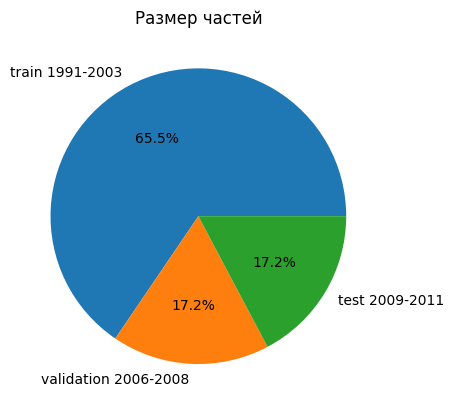

In [54]:
sizes = [train_hockey_df.shape[0], val_hockey_df.shape[0], test_hockey_df.shape[0]]
plt.pie(sizes, labels=["train 1991-2003", "validation 2006-2008", "test 2009-2011"], autopct="%1.1f%%")
plt.title("Размер частей")
plt.show()

Доля классов в train, validation, test

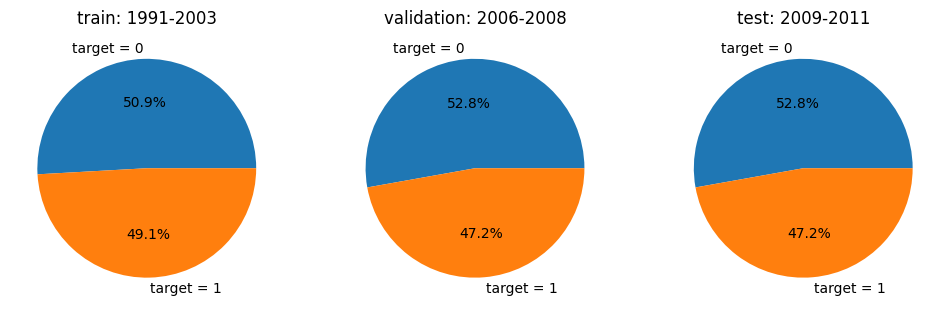

In [55]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.pie(train_hockey_df["target"].value_counts().sort_index(), labels=["target = 0", "target = 1"], autopct="%1.1f%%")
plt.title("train: 1991-2003")

plt.subplot(1, 3, 2)
plt.pie(val_hockey_df["target"].value_counts().sort_index(), labels=["target = 0", "target = 1"], autopct="%1.1f%%")
plt.title("validation: 2006-2008")

plt.subplot(1, 3, 3)
plt.pie(test_hockey_df["target"].value_counts().sort_index(), labels=["target = 0", "target = 1"], autopct="%1.1f%%")
plt.title("test: 2009-2011")

plt.show()

Столбцы, которые появились при построении target.

In [56]:
hockey_df_timediff.columns.difference(hockey_df.columns)

Index(['goal_diff_next', 'goals_against_next', 'goals_for_next', 'losses_next',
       'median_next', 'ot_losses_next', 'target', 'target_year',
       'win_rate_next', 'wins_next'],
      dtype='object')

**Ответ 2.2:**

Разделил пары по году целевого сезона target_year. Фактические годы и размеры частей видны в выводе value_counts и в таблице выше: train — 1991-2003, 338 пар (65.5%), доля класса 1 0.491; validation — 2006-2008, 89 пар (17.2%), доля класса 1 0.472; test — 2009-2011, 89 пар (17.2%), доля класса 1 0.472. Train заканчивается на 2003 году, хотя граница 2005: сезона 2004 нет, поэтому нет и пар с целевыми годами 2004 и 2005. В validation и test по 89 пар, а не по 90: в 2006 году нет пары у Mighty Ducks of Anaheim (переименование), в 2011 — у Atlanta Thrashers (переезд). Классы во всех частях распределены почти поровну, а обучающая часть значительно больше validation и test.

При построении target появились столбцы, которые недоступны модели в момент прогноза (вывод columns.difference выше): все столбцы с _next, например win_rate_next и wins_next, а также median_next. Они описывают сезон t+1, который ещё не сыгран, когда прогноз делается после сезона t, а target строится прямо из win_rate_next и median_next. target_year не утечка: это year + 1, он известен заранее. Поэтому признаки для модели задаю явным списком столбцов сезона t.

Случайное перемешивание строк отвечало бы на вопрос, насколько хорошо модель угадывает класс для случайного сезона, если она видела соседние и даже более поздние сезоны. В train попали бы сезоны позже сезонов из test. Кроме того, доля побед команды в сезоне t+1, из которой строится её target, является признаком win_rate в строке этой же команды за следующий год, и эта строка могла бы оказаться в train. Ещё перемешивание смешало бы эпохи с ничьими и без них и скрыло бы сдвиг между ними. Временная схема отвечает на реальный вопрос: насколько хорошо модель, обученная на прошлых сезонах, предсказывает будущие.

## Раздел 3. Исследовательский анализ: 20 баллов

### 3.1. Сформулируйте вопросы к данным

До построения основных графиков сформулируйте не менее двух собственных
исследовательских вопросов, связанных с будущей успешностью команд
или устройством данных. Для каждого запишите ожидаемый результат и объясните,
как ответ может повлиять на выбор признаков, обработку или интерпретацию модели.

Добавляю в каждую часть число матчей в сезоне t.

In [57]:
train_hockey_df["games"] = (train_hockey_df["wins"] / train_hockey_df["win_rate"]).round()
val_hockey_df["games"] = (val_hockey_df["wins"] / val_hockey_df["win_rate"]).round()
test_hockey_df["games"] = (test_hockey_df["wins"] / test_hockey_df["win_rate"]).round()

Разница голов за матч. Делю на число матчей, потому что длина сезонов разная. Признак считается только по данным сезона t.

In [58]:
train_hockey_df["goal_diff_per_game"] = train_hockey_df["goal_diff"] / train_hockey_df["games"]
val_hockey_df["goal_diff_per_game"] = val_hockey_df["goal_diff"] / val_hockey_df["games"]
test_hockey_df["goal_diff_per_game"] = test_hockey_df["goal_diff"] / test_hockey_df["games"]

**Ответ 3.1:**

Зависимость от target изучаю только на train. Для вопроса 3 сравниваю признаки train и validation без target. Для анализа и модели добавил число матчей и разницу голов за матч, так как длина сезонов разная.

**Вопрос 1.** Сохраняется ли успешность команды в следующем сезоне? Ожидаю, что команды выше медианы чаще остаются выше медианы, но результат частично возвращается к среднему: сильные немного слабеют, слабые немного усиливаются. Если связь сильная, win_rate будет главным признаком, а простой ориентир по win_rate будет трудно обойти. Возврат к среднему означает, что модель не должна давать слишком уверенных прогнозов.

**Вопрос 2.** Даёт ли разница голов дополнительную информацию о будущем успехе по сравнению с долей побед? Ожидаю, что да: разница голов меньше зависит от удачи в равных матчах (ничьи, овертаймы), поэтому команды с хорошей разницей голов, но невысокой долей побед, чаще улучшаются. От ответа зависит, добавлять ли goal_diff_per_game в модель.

**Вопрос 3.** Сопоставимы ли значения признаков в периоде train и в периоде validation? Ожидаю, что нет: после отмены ничьих в 2005 году доля побед в среднем выросла, а результативность в разные годы разная. Если уровень win_rate сдвинулся, модель, обученная на абсолютном win_rate, будет сдвигать вероятности на validation и test. Тогда нужен признак относительно медианы сезона, это проверяю в 4.3.

### 3.2. Проведите исследовательский анализ

Ответьте на вопросы из пункта 3.1 с помощью числовых сводок и визуализаций.
Количество и типы графиков выберите сами: их должно быть достаточно,
чтобы подтвердить выводы, а каждый график должен отвечать на сформулированный вопрос.
Покажите хотя бы одно конкретное наблюдение на уровне команды или сезона.
Для каждого вывода укажите ограничение интерпретации.

**Вопрос 1.** Доля побед команды в сезонах t и t+1 на train. Пунктир - это линия, на которой доля побед не изменилась.

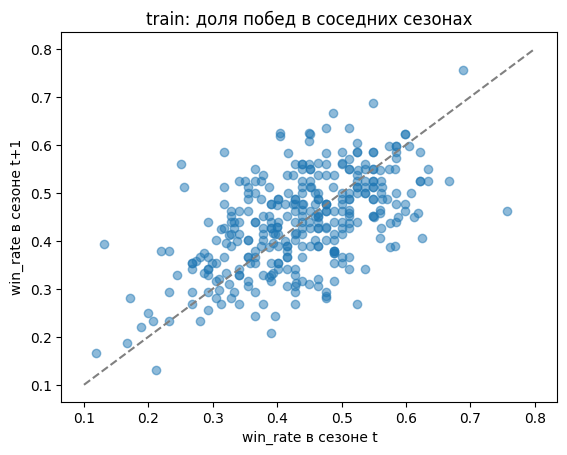

In [59]:
plt.scatter(train_hockey_df["win_rate"], train_hockey_df["win_rate_next"], alpha=0.5)
plt.plot([0.1, 0.8], [0.1, 0.8], color="gray", linestyle="--")
plt.xlabel("win_rate в сезоне t")
plt.ylabel("win_rate в сезоне t+1")
plt.title("train: доля побед в соседних сезонах")
plt.show()

Делю команды train на 4 равные группы по win_rate и смотрю среднюю долю побед в следующем сезоне и долю target = 1.

In [60]:
train_hockey_df.groupby(pd.qcut(train_hockey_df["win_rate"], 4), observed=True)[["win_rate", "win_rate_next", "target"]].mean().round(3)

,win_rate,win_rate_next,target
win_rate,,,
"(0.118, 0.366]",0.305,0.369,0.211
"(0.366, 0.439]",0.410,0.424,0.360
"(0.439, 0.512]",0.479,0.462,0.596
"(0.512, 0.756]",0.571,0.513,0.863


Медиана win_rate каждого сезона по полной таблице. Отмечаю команды train, которые в сезоне t были выше медианы своего сезона.

In [61]:
season_median = hockey_df.groupby("year")["win_rate"].median()
train_hockey_df["above_median"] = train_hockey_df["win_rate"] > train_hockey_df["year"].map(season_median)

Как часто команда выше медианы в сезоне t остаётся выше медианы в сезоне t+1 (доли по строкам).

In [62]:
pd.crosstab(train_hockey_df["above_median"], train_hockey_df["target"], normalize="index").round(3)

target,0,1
above_median,,
False,0.709,0.291
True,0.294,0.706


**Вопрос 2.** Корреляции доли побед и разницы голов за матч в сезоне t с долей побед в сезоне t+1 на train.

In [63]:
train_hockey_df[["win_rate", "goal_diff_per_game", "win_rate_next"]].corr().round(3)

,win_rate,goal_diff_per_game,win_rate_next
win_rate,1.000,0.942,0.561
goal_diff_per_game,0.942,1.000,0.565
win_rate_next,0.561,0.565,1.000


ROC-AUC каждого признака по отдельности на train: насколько хорошо он сам по себе упорядочивает будущий класс.

In [64]:
print("win_rate:", round(roc_auc_score(train_hockey_df["target"], train_hockey_df["win_rate"]), 3))
print("goal_diff_per_game:", round(roc_auc_score(train_hockey_df["target"], train_hockey_df["goal_diff_per_game"]), 3))

win_rate: 0.778
goal_diff_per_game: 0.776


Случаи, где доля побед и разница голов расходятся: число команд и доля target = 1 в каждой группе.

In [65]:
train_hockey_df["goal_diff_positive"] = train_hockey_df["goal_diff"] > 0
train_hockey_df.groupby(["above_median", "goal_diff_positive"])["target"].agg(["count", "mean"]).round(3)

count   mean
above_median goal_diff_positive              
False        False                 148  0.257
             True                   27  0.481
True         False                  10  0.500
             True                  153  0.719

Разница голов за матч и доля побед на train, цветом показан target. Подписан пример Buffalo Sabres 1992.

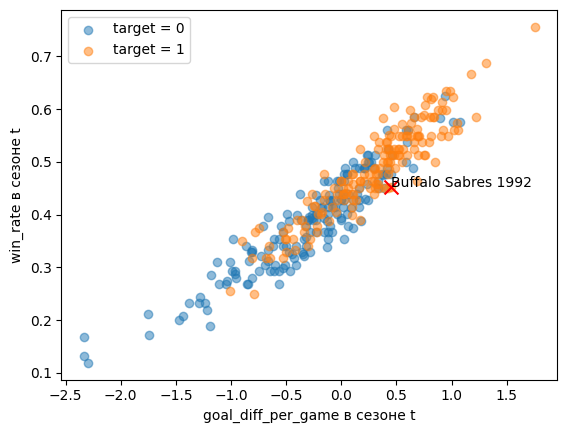

In [66]:
train_0 = train_hockey_df[train_hockey_df["target"] == 0]
train_1 = train_hockey_df[train_hockey_df["target"] == 1]
buffalo = train_hockey_df[(train_hockey_df["team"] == "Buffalo Sabres") & (train_hockey_df["year"] == 1992)]

plt.scatter(train_0["goal_diff_per_game"], train_0["win_rate"], alpha=0.5, label="target = 0")
plt.scatter(train_1["goal_diff_per_game"], train_1["win_rate"], alpha=0.5, label="target = 1")
plt.scatter(buffalo["goal_diff_per_game"], buffalo["win_rate"], color="red", marker="x", s=100)
plt.annotate("Buffalo Sabres 1992", (buffalo["goal_diff_per_game"].iloc[0], buffalo["win_rate"].iloc[0]))
plt.xlabel("goal_diff_per_game в сезоне t")
plt.ylabel("win_rate в сезоне t")
plt.legend()
plt.show()

Пример на уровне команды: Buffalo Sabres 1992.

In [67]:
buffalo[["team", "year", "win_rate", "goal_diff", "goal_diff_per_game", "win_rate_next", "median_next", "target"]]

,team,year,win_rate,goal_diff,goal_diff_per_game,win_rate_next,median_next,target
44,Buffalo Sabres,1992,0.452,38,0.452381,0.512,0.464,1


Медиана сезона 1992 для сравнения.

In [68]:
print(season_median[1992])

0.476


**Вопрос 3.** Беру сезоны до 2007 года включительно: это сезоны признаков train и validation. Считаю медиану win_rate и голов за матч в каждом сезоне.

In [69]:
era_df = hockey_df[hockey_df["year"] <= 2007].copy()
era_df["goals_per_game"] = era_df["goals_for"] / (era_df["wins"] / era_df["win_rate"]).round()
season_stats = era_df.groupby("year")[["win_rate", "goals_per_game"]].median()
season_stats.round(3)

,win_rate,goals_per_game
year,,
1990,0.425,3.400
1991,0.444,3.525
1992,0.476,3.815
1993,0.464,3.327
1994,0.428,2.833
1995,0.433,3.043
1996,0.427,2.884
1997,0.427,2.659
1998,0.415,2.573


Те же медианы на графиках. Пунктир - это пропущенный сезон 2004.

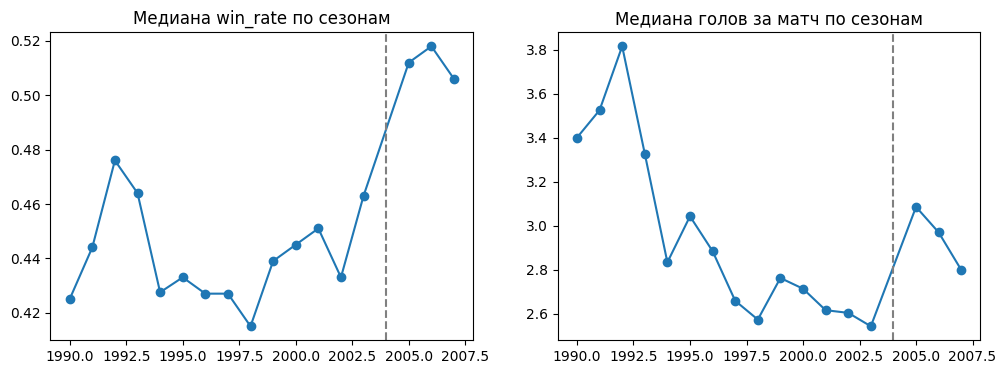

In [70]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(season_stats.index, season_stats["win_rate"], marker="o")
plt.axvline(2004, color="gray", linestyle="--")
plt.title("Медиана win_rate по сезонам")

plt.subplot(1, 2, 2)
plt.plot(season_stats.index, season_stats["goals_per_game"], marker="o")
plt.axvline(2004, color="gray", linestyle="--")
plt.title("Медиана голов за матч по сезонам")

plt.show()

Сумма разницы голов всех команд в каждом сезоне, максимум по модулю. В закрытой лиге каждый гол одной команды пропущен другой, поэтому сумма должна быть равна нулю.

In [71]:
print(hockey_df.groupby("year")["goal_diff"].sum().abs().max())

0


Сравниваю медианы признаков в train и validation (без target).

In [72]:
pd.DataFrame({
  "train": train_hockey_df[["win_rate", "goal_diff_per_game"]].median(),
  "validation": val_hockey_df[["win_rate", "goal_diff_per_game"]].median(),
}).round(3)

,train,validation
win_rate,0.439,0.512
goal_diff_per_game,0.042,0.049


**Ответ 3.2:**

**Вопрос 1.** На графике точки лежат вдоль диагонали, но облако положе диагонали: сильные команды в следующем сезоне в среднем немного слабеют, слабые немного усиливаются. Корреляция win_rate в сезонах t и t+1 на train 0.561. У верхней четверти команд средняя доля побед 0.571, а в следующем сезоне 0.513, у нижней четверти 0.305 и 0.369 (таблица по четвертям). Команды выше медианы своего сезона остаются выше медианы в следующем сезоне в 70.6% случаев, а команды ниже медианы поднимаются выше в 29.1% случаев. Вывод: успешность сохраняется заметно, но не полностью, поэтому win_rate будет главным признаком, ориентир по win_rate будет сильным, а уверенность модели должна быть умеренной. Ограничение: это только сезоны train (1991-2003, эпоха с ничьими), а корреляция показывает связь, но не объясняет её причины.

**Вопрос 2.** По отдельности разница голов за матч и доля побед почти одинаково связаны с будущим: корреляция с win_rate_next 0.565 и 0.561, ROC-AUC на train 0.776 и 0.778. Между собой они связаны очень сильно (0.942), то есть в основном несут одну и ту же информацию. Но там, где они расходятся, разница голов помогает. Из команд ниже медианы с положительной разницей голов в следующем сезоне выше медианы оказались 48.1% (27 команд), а с неположительной только 25.7%. Из команд выше медианы с неположительной разницей голов выше медианы остались 50.0% (10 команд), а с положительной 71.9%. Пример на уровне команды: Buffalo Sabres 1992 (красный крестик на графике) имели долю побед 0.452 при медиане сезона 0.476, но разницу голов +38 (+0.45 за матч), и в 1993 году их доля побед 0.512 оказалась выше медианы 0.464, target = 1. Вывод: goal_diff_per_game стоит добавить в модель вместе с win_rate, но прирост будет небольшим, потому что признаки расходятся только у 37 из 338 команд. Ограничение: группы с расхождением маленькие (27 и 10 команд), один пример только иллюстрирует вывод, а часть расхождений может объясняться ничьими, которых в validation и test уже нет.

**Вопрос 3.** Медиана win_rate в сезонах 1990-2003 от 0.415 до 0.476, а в 2005-2007 от 0.506 до 0.518 (таблица и левый график). Медиана win_rate в train 0.439, в validation 0.512. Наблюдение на уровне сезона: в 2005 году после локаута и отмены ничьих доля побед резко выросла, потому что матчи, которые раньше заканчивались ничьей, теперь кто-то выигрывает. Голов за матч тоже было по-разному: 3.815 в 1992 году, 2.543 в 2003 и 3.085 в 2005 (правый график). Разница голов за матч не сдвигается: сумма разницы голов в каждом сезоне равна нулю, а медианы в train и validation 0.042 и 0.049. Вывод: абсолютный win_rate в train и validation не сопоставим, и модель, обученная на train, будет считать большинство команд validation сильными. Абсолютные числа голов в модель брать не стоит, а win_rate стоит сравнивать с медианой сезона, это проверяю в 4.3. Ограничение: я сравнивал только медианы; причина сдвига win_rate (ничьи) подтверждена в 1.2, а причины изменения результативности (например, изменения правил) в этих данных не проверить. Test здесь не использовался.

## Раздел 4. Модели и эксперименты: 25 баллов

### 4.1. Постройте ориентиры

На train обучите простой константный baseline и оцените его на validation.
Отдельно используйте текущий `win_rate` как простую оценку для ранжирования
будущего класса. Посчитайте ROC-AUC обоих ориентиров и объясните,
какую планку задаёт каждый из них для обучаемой модели.

Константный baseline на train запоминает долю класса 1 и всем командам выдаёт её как вероятность. Признак передаю, т.к. этого требует sklearn, он не используется.

In [73]:
dummy_model = DummyClassifier(strategy="prior")
dummy_model.fit(train_hockey_df[["win_rate"]], train_hockey_df["target"])
dummy_val_proba = dummy_model.predict_proba(val_hockey_df[["win_rate"]])[:, 1]
round(roc_auc_score(val_hockey_df["target"], dummy_val_proba), 3)

np.float64(0.5)

Текущий win_rate как оценка для ранжирования

In [74]:
round(roc_auc_score(val_hockey_df["target"], val_hockey_df["win_rate"]), 3)

np.float64(0.757)

**Ответ 4.1:**

Константный baseline запомнил на train долю класса 1 (0.491) и всем командам validation выдаёт одну и ту же вероятность, поэтому его ROC-AUC 0.5. Модель с ROC-AUC не выше 0.5 упорядочивает команды не лучше случайного угадывания.

Текущий win_rate без всякого обучения даёт на validation ROC-AUC 0.757. Это настоящая планка для модели: информация о текущей успешности уже есть в одном столбце, и обучаемая модель имеет смысл, только если превосходит 0.757, то есть добавляет что-то сверх доли побед.

### 4.2. Постройте первую модель

Обучите логистическую регрессию. Самостоятельно выберите признаки и обоснуйте выбор.
Обработку пропусков и масштабирование включите в Pipeline и обучайте только на train.
Посчитайте ROC-AUC на validation и сравните с обоими ориентирами.
Объясните результат без использования test.

Признаки первой модели: доля побед и разница голов за матч в сезоне t.

In [75]:
features = ["win_rate", "goal_diff_per_game"]

Pipeline: заполнение пропусков медианой, масштабирование и логистическая регрессия. Медиана и параметры масштабирования считаются только на train при fit.

In [76]:
first_model = Pipeline([
  ("imputer", SimpleImputer(strategy="median")),
  ("scaler", StandardScaler()),
  ("model", LogisticRegression()),
])
first_model.fit(train_hockey_df[features], train_hockey_df["target"])

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()), ('model', LogisticRegression())])

Вероятности класса 1 на validation и ROC-AUC.

In [77]:
first_val_proba = first_model.predict_proba(val_hockey_df[features])[:, 1]
round(roc_auc_score(val_hockey_df["target"], first_val_proba), 3)

np.float64(0.771)

Сравнение с ориентирами на validation.

In [78]:
pd.DataFrame({
  "ROC-AUC validation": [
    roc_auc_score(val_hockey_df["target"], dummy_val_proba),
    roc_auc_score(val_hockey_df["target"], val_hockey_df["win_rate"]),
    roc_auc_score(val_hockey_df["target"], first_val_proba),
  ],
}, index=["константа", "win_rate", "логистическая регрессия"]).round(3)

,ROC-AUC validation
константа,0.500
win_rate,0.757
логистическая регрессия,0.771


Коэффициенты модели (признаки масштабированы, поэтому их можно сравнивать между собой).

In [79]:
pd.Series(first_model.named_steps["model"].coef_[0], index=features).round(3)

,0
win_rate,0.780
goal_diff_per_game,0.494


Проверяю, как модель ставит класс при пороге 0.5: доля прогнозов класса 1 и средняя вероятность против реальной доли класса 1 в validation.

In [80]:
print("Доля прогнозов класса 1:", round(first_model.predict(val_hockey_df[features]).mean(), 3))
print("Средняя вероятность:", round(first_val_proba.mean(), 3))
print("Реальная доля класса 1:", round(val_hockey_df["target"].mean(), 3))

Доля прогнозов класса 1: 0.697
Средняя вероятность: 0.587
Реальная доля класса 1: 0.472


**Ответ 4.2:**

Признаки: win_rate и goal_diff_per_game сезона t. win_rate - главный сигнал (вопрос 1 в 3.2), goal_diff_per_game добавляет информацию там, где доля побед и разница голов расходятся (вопрос 2). Разницу голов делю на число матчей, потому что сезоны разной длины. Не беру wins, losses, goals_for и goals_against в абсолютных числах, так как они зависят от длины сезона и уровня результативности (вопрос 3). Не беру ot_losses, так как до 1999 года он равен 0 из-за правил, а не из-за игры команды. Не беру year, так как это не характеристика команды, и модели пришлось бы переносить его на годы, которых не было в train. Все столбцы с _next, median_next и target не беру, так как это будущее.

Pipeline: SimpleImputer(strategy="median"), StandardScaler и LogisticRegression, обучение только на train. В выбранных признаках пропусков нет, но imputer оставил для надёжности; его медианы, как и параметры масштабирования, считаются только на train.

На validation ROC-AUC модели 0.771, у win_rate 0.757, у константы 0.5. Модель выше обоих ориентиров, но прирост над win_rate небольшой (0.014), и на 89 строках он сравним со случайным разбросом. Оба коэффициента положительные (0.780 у win_rate и 0.494 у goal_diff_per_game), главный вклад даёт win_rate.

При пороге 0.5 модель ставит класс 1 для 69.7% команд validation, средняя вероятность 0.587, а реальная доля класса 1 0.472. Причина в сдвиге: в validation доля побед в среднем выше (0.512 против 0.439 в train), и модель, обученная на эпохе с ничьими, считает большинство команд сильными. ROC-AUC этого почти не видит, потому что проверяет только порядок команд, а F1 и accuracy при пороге 0.5 от этого зависят напрямую.

### 4.3. Проведите собственный эксперимент

Выберите одно осмысленное изменение: состав признаков, способ обработки данных,
параметры или другой алгоритм. До запуска запишите ожидаемый эффект и его причину.
Изменяйте одну понятную часть решения, сравните варианты на validation
и зафиксируйте выбор финальной модели до просмотра test.
Дополнительные эксперименты допустимы, но их количество само по себе не оценивается.

**Изменение:** заменяю win_rate на win_rate_rel, то есть разницу между долей побед команды и медианой её сезона t. Разницу голов за матч не меняю: в закрытой лиге её среднее в каждом сезоне равно нулю, она и так относительная.

**Ожидание:** в 3.2 уровень win_rate в validation выше, чем в train, из-за отмены ничьих, и в 4.2 модель ставит класс 1 слишком многим командам. Относительный признак убирает этот сдвиг. ROC-AUC почти не изменится, потому что сезоны внутри validation похожи и порядок команд почти тот же. Должна стать правильной доля прогнозов класса 1 и вырасти accuracy при пороге 0.5.

**Правило выбора:** основная метрика ROC-AUC на validation. Если новый вариант хуже не больше чем на 0.01 (на 89 строках это меньше случайного разброса), выбираю его, потому что он не зависит от уровня win_rate в эпохе и ставит класс 1 примерно с правильной частотой. Если хуже сильнее, оставляю первую модель.

Добавляю win_rate_rel в каждую часть. Медиана берётся по полной таблице сезона t, она известна после окончания сезона t.

In [81]:
train_hockey_df["win_rate_rel"] = train_hockey_df["win_rate"] - train_hockey_df["year"].map(season_median)
val_hockey_df["win_rate_rel"] = val_hockey_df["win_rate"] - val_hockey_df["year"].map(season_median)
test_hockey_df["win_rate_rel"] = test_hockey_df["win_rate"] - test_hockey_df["year"].map(season_median)

Та же модель, меняется только признак win_rate на win_rate_rel.

In [82]:
features_rel = ["win_rate_rel", "goal_diff_per_game"]
rel_model = Pipeline([
  ("imputer", SimpleImputer(strategy="median")),
  ("scaler", StandardScaler()),
  ("model", LogisticRegression()),
])
rel_model.fit(train_hockey_df[features_rel], train_hockey_df["target"])

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()), ('model', LogisticRegression())])

Сравниваю два варианта на validation.

In [83]:
rel_val_proba = rel_model.predict_proba(val_hockey_df[features_rel])[:, 1]

pd.DataFrame({
  "ROC-AUC": [
    roc_auc_score(val_hockey_df["target"], first_val_proba),
    roc_auc_score(val_hockey_df["target"], rel_val_proba),
  ],
  "accuracy": [
    accuracy_score(val_hockey_df["target"], first_model.predict(val_hockey_df[features])),
    accuracy_score(val_hockey_df["target"], rel_model.predict(val_hockey_df[features_rel])),
  ],
  "F1": [
    f1_score(val_hockey_df["target"], first_model.predict(val_hockey_df[features])),
    f1_score(val_hockey_df["target"], rel_model.predict(val_hockey_df[features_rel])),
  ],
  "доля прогнозов класса 1": [
    first_model.predict(val_hockey_df[features]).mean(),
    rel_model.predict(val_hockey_df[features_rel]).mean(),
  ],
}, index=["win_rate", "win_rate_rel"]).round(3)

,ROC-AUC,accuracy,F1,доля прогнозов класса 1
win_rate,0.771,0.708,0.750,0.697
win_rate_rel,0.768,0.719,0.706,0.483


Фиксирую финальное решение до просмотра test: модель с win_rate_rel и goal_diff_per_game, обученная на train.

In [84]:
final_model = rel_model
final_features = features_rel
final_features

['win_rate_rel', 'goal_diff_per_game']

**Ответ 4.3:**

Изменение, ожидание и правило выбора записаны в описании перед кодом до запуска. Заменил win_rate на win_rate_rel (доля побед минус медиана сезона t), остальное в модели не менял.

Результат на validation: ROC-AUC изменился с 0.771 до 0.768 (−0.003), accuracy с 0.708 до 0.719, доля прогнозов класса 1 с 0.697 до 0.483 при реальной доле 0.472. Ожидание подтвердилось: порядок команд почти не изменился, а класс 1 стал ставиться с правильной частотой. F1 снизился с 0.750 до 0.706. Это не ухудшение качества: F1 считается только по классу 1, и первая модель получала высокий F1 за счёт того, что отмечала классом 1 почти 70% команд и поэтому находила больше настоящих единиц.

ROC-AUC хуже меньше чем на 0.01, поэтому по правилу выбираю вариант с win_rate_rel. Финальное решение зафиксировано до просмотра test: признаки win_rate_rel и goal_diff_per_game, Pipeline из SimpleImputer(strategy="median"), StandardScaler и LogisticRegression с параметрами по умолчанию, обучение на train.

## Раздел 5. Итоговая оценка и анализ ошибок: 15 баллов

### 5.1. Проведите итоговую оценку

Зафиксируйте выбранную модель, признаки и параметры, затем один раз оцените её на test.
Покажите ROC-AUC, F1 и accuracy при пороге 0.5 для выбранной модели
и сопоставимых baseline. Объясните различия между метриками и сравните
результаты validation и test. После этого не меняйте выбранное решение.

Один раз считаю прогнозы финальной модели на test. Класс при пороге 0.5 даёт predict.

In [85]:
test_proba = final_model.predict_proba(test_hockey_df[final_features])[:, 1]
test_pred = final_model.predict(test_hockey_df[final_features])

Прогнозы ориентиров на test. Для win_rate порог 0.5 означает правило «команда выиграла больше половины матчей». Константа предсказывает класс 0 для всех.

In [86]:
dummy_test_proba = dummy_model.predict_proba(test_hockey_df[["win_rate"]])[:, 1]
dummy_test_pred = dummy_model.predict(test_hockey_df[["win_rate"]])
win_rate_test_pred = (test_hockey_df["win_rate"] > 0.5).astype(int)

Метрики на test.

In [87]:
pd.DataFrame({
  "ROC-AUC": [
    roc_auc_score(test_hockey_df["target"], test_proba),
    roc_auc_score(test_hockey_df["target"], test_hockey_df["win_rate"]),
    roc_auc_score(test_hockey_df["target"], dummy_test_proba),
  ],
  "F1": [
    f1_score(test_hockey_df["target"], test_pred),
    f1_score(test_hockey_df["target"], win_rate_test_pred),
    f1_score(test_hockey_df["target"], dummy_test_pred, zero_division=0),
  ],
  "accuracy": [
    accuracy_score(test_hockey_df["target"], test_pred),
    accuracy_score(test_hockey_df["target"], win_rate_test_pred),
    accuracy_score(test_hockey_df["target"], dummy_test_pred),
  ],
}, index=["финальная модель", "win_rate", "константа"]).round(3)

,ROC-AUC,F1,accuracy
финальная модель,0.756,0.667,0.674
win_rate,0.740,0.659,0.674
константа,0.500,0.000,0.528


Те же метрики на validation, чтобы сравнить с test.

In [88]:
rel_val_pred = rel_model.predict(val_hockey_df[features_rel])
win_rate_val_pred = (val_hockey_df["win_rate"] > 0.5).astype(int)
dummy_val_pred = dummy_model.predict(val_hockey_df[["win_rate"]])

pd.DataFrame({
  "ROC-AUC": [
    roc_auc_score(val_hockey_df["target"], rel_val_proba),
    roc_auc_score(val_hockey_df["target"], val_hockey_df["win_rate"]),
    roc_auc_score(val_hockey_df["target"], dummy_val_proba),
  ],
  "F1": [
    f1_score(val_hockey_df["target"], rel_val_pred),
    f1_score(val_hockey_df["target"], win_rate_val_pred),
    f1_score(val_hockey_df["target"], dummy_val_pred, zero_division=0),
  ],
  "accuracy": [
    accuracy_score(val_hockey_df["target"], rel_val_pred),
    accuracy_score(val_hockey_df["target"], win_rate_val_pred),
    accuracy_score(val_hockey_df["target"], dummy_val_pred),
  ],
}, index=["финальная модель", "win_rate", "константа"]).round(3)

,ROC-AUC,F1,accuracy
финальная модель,0.768,0.706,0.719
win_rate,0.757,0.733,0.730
константа,0.500,0.000,0.528


**Ответ 5.1:**

Финальную модель оценил на test один раз: ROC-AUC 0.756, F1 0.667, accuracy 0.674. У win_rate ROC-AUC 0.740, F1 0.659, accuracy 0.674, у константы 0.5, 0 и 0.528.

Метрики показывают разное. ROC-AUC проверяет, насколько хорошо упорядочены команды при всех порогах сразу: здесь модель немного лучше win_rate. F1 и accuracy проверяют прогнозы при одном пороге 0.5: здесь модель и правило «win_rate > 0.5» ошибаются одинаково часто (accuracy 0.674), то есть при фиксированном пороге преимущество модели не видно. Константа хорошо показывает разницу метрик: она всегда предсказывает класс 0, поэтому accuracy у неё 0.528 (доля класса 0), но F1 = 0, потому что она не находит ни одной команды класса 1.

На validation у модели ROC-AUC 0.768, F1 0.706, accuracy 0.719, на test все три метрики ниже. Но у win_rate тоже падение (ROC-AUC 0.757 → 0.740), то есть сезоны test в целом труднее предсказать. На validation правило «win_rate > 0.5» по accuracy и F1 было даже немного лучше модели (0.730 и 0.733). Порядок методов по ROC-AUC на обеих частях одинаковый: модель, затем win_rate, затем константа. Разница между validation и test сравнима со случайным разбросом на 89 строках. Решение после test не меняю.

### 5.2. Разберите ошибки

Выберите от трёх до пяти ошибок финальной модели по явно указанному принципу.
Это могут быть наиболее уверенные ошибки, отдельный тип ошибки или другой
обоснованный набор. Покажите идентификаторы строк, вероятности и значения,
необходимые для анализа. Найдите общие черты и различия; отделите факты
из таблицы от гипотез и назовите данные, нужные для проверки одной гипотезы.

Добавляю в test вероятность, прогноз и размер ошибки: модуль разницы между вероятностью и настоящим классом.

In [89]:
test_hockey_df["proba"] = test_proba
test_hockey_df["pred"] = test_pred
test_hockey_df["error_size"] = (test_hockey_df["proba"] - test_hockey_df["target"]).abs()

Матрица ошибок на test: строки — настоящий класс, столбцы — прогноз.

In [90]:
pd.crosstab(test_hockey_df["target"], test_hockey_df["pred"])

pred,0,1
target,,
0,31,16
1,13,29


Принцип выбора: 5 самых уверенных ошибок, то есть ошибки с наибольшим размером ошибки. Индекс слева — идентификатор строки.

In [91]:
test_errors = test_hockey_df[test_hockey_df["pred"] != test_hockey_df["target"]]
top_errors = test_errors.sort_values("error_size", ascending=False).head(5)
top_errors[["team", "year", "win_rate", "win_rate_rel", "goal_diff", "goal_diff_per_game", "proba", "target", "win_rate_next", "median_next"]].round(3)

,team,year,win_rate,win_rate_rel,goal_diff,goal_diff_per_game,proba,target,win_rate_next,median_next
464,Boston Bruins,2008,0.646,0.146,78,0.951,0.864,0,0.476,0.488
470,Colorado Avalanche,2008,0.390,-0.110,-58,-0.707,0.187,1,0.524,0.488
514,Phoenix Coyotes,2009,0.610,0.122,23,0.280,0.755,0,0.524,0.524
518,Tampa Bay Lightning,2009,0.415,-0.073,-43,-0.524,0.262,1,0.561,0.524
509,New Jersey Devils,2009,0.585,0.097,31,0.378,0.733,0,0.463,0.524


Насколько изменилась доля побед у этих команд между сезонами t и t+1.

In [92]:
(top_errors["win_rate_next"] - top_errors["win_rate"]).round(3)

,0
464,-0.170
470,0.134
514,-0.086
518,0.146
509,-0.122


Для сравнения: среднее абсолютное изменение доли побед у всех команд test.

In [93]:
print(round((test_hockey_df["win_rate_next"] - test_hockey_df["win_rate"]).abs().mean(), 3))

0.067


**Ответ 5.2:**

На test модель ошиблась в 29 случаях из 89: 16 ложных прогнозов класса 1 и 13 пропущенных команд класса 1 (матрица ошибок). Принцип выбора: 5 самых уверенных ошибок, то есть с наибольшей разницей между вероятностью и настоящим классом. Это строки 464 (Boston Bruins 2008, вероятность 0.864, target 0), 470 (Colorado Avalanche 2008, 0.187, target 1), 514 (Phoenix Coyotes 2009, 0.755, target 0), 518 (Tampa Bay Lightning 2009, 0.262, target 1) и 509 (New Jersey Devils 2009, 0.733, target 0).

Факты из таблицы. Общее: во всех пяти случаях доля побед и разница голов в сезоне t указывали в одну сторону (обе выше медианы или обе ниже), поэтому модель была уверена. Во всех пяти случаях доля побед сильно изменилась к следующему сезону: на 0.086-0.170 по модулю при среднем изменении 0.067 у всех команд test. Различия: три ошибки — сильные команды, которые упали (Boston −0.170, New Jersey −0.122, Phoenix −0.086), две — слабые команды, которые выросли (Colorado +0.134, Tampa Bay +0.146). Phoenix Coyotes 2009 — пограничный случай: доля побед в 2010 году 0.524 ровно равна медиане 0.524, и по строгому правилу target = 0, хотя команда не провалилась. У Boston Bruins 2008 самая большая разница голов среди пяти (+78), но в следующем сезоне доля побед оказалась на 0.012 ниже медианы.

Гипотезы (в нашей таблице их не проверить). Резкие изменения могут быть связаны с составом (уход или травмы ключевых игроков, смена тренера) или с удачей в сезоне t, которая не повторилась. Одна гипотеза для проверки: сильные команды, которые упали, в сезоне t выигрывали за счёт необычно высокого процента отражённых бросков у вратаря и процента реализации бросков, и к сезону t+1 эти проценты снизились. Для проверки нужны броски в створ (свои и соперников) по каждой команде и сезону, которых нет в нашей таблице.

## Раздел 6. Выводы и воспроизводимость: 5 баллов

### 6.1. Сформулируйте выводы

Сформулируйте основные выводы и ограничения работы со ссылками на свои графики,
строки и метрики. Опишите минимум два решения, которые вы изменили
или подтвердили после получения результатов. Назовите одно улучшение,
которое вы сознательно не стали выполнять, и объясните причину.
Убедитесь, что последовательность работы и финальные параметры можно воспроизвести.

Версии библиотек и финальные параметры для воспроизведения. LogisticRegression с решателем lbfgs детерминирована, случайности в решении нет.

In [94]:
import sklearn
print("pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)
print("Признаки:", final_features)
final_model

pandas 2.2.3 | numpy 2.1.3 | scikit-learn 1.6.1
Признаки: ['win_rate_rel', 'goal_diff_per_game']


Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()), ('model', LogisticRegression())])

**Ответ 6.1:**

1. Построил 516 пар сезонов с target по медиане полной таблицы будущего сезона и разделил их по времени: 338 пар в train, по 89 в validation и test, классы почти сбалансированы (2.1, 2.2).
2. Успешность команды сохраняется заметно, но с возвратом к среднему: корреляция долей побед соседних сезонов 0.561, команды выше медианы остаются выше в 70.6% случаев (3.2, вопрос 1).
3. Разница голов за матч сама по себе почти так же информативна, как доля побед, и помогает там, где они расходятся (3.2, вопрос 2).
4. Между эпохами есть сдвиг: после отмены ничьих медиана win_rate выросла с 0.439 в train до 0.512 в validation (3.2, вопрос 3). Из-за него первая модель ставила класс 1 почти 70% команд validation (4.2).
5. Финальная модель (логистическая регрессия на win_rate_rel и goal_diff_per_game) на test даёт ROC-AUC 0.756 против 0.740 у win_rate и 0.5 у константы, а accuracy 0.674 такая же, как у правила «win_rate > 0.5» (5.1). Основная информация о будущем уже есть в текущей доле побед, модель немного улучшает упорядочивание команд.

Ограничения: в validation и test по 89 строк, поэтому разница в 0.01-0.02 ROC-AUC сравнима со случайным разбросом. В данных только семь показателей сезона, нет информации о составе, травмах и бросках, а самые уверенные ошибки связаны как раз с резкими изменениями между сезонами (5.2). Команды, которые переехали или сменили название, исключены (6 строк). Train полностью относится к эпохе с ничьими, а validation и test к эпохе без них.

Решения, изменённые или подтверждённые после результатов:
- Изменил: заменил win_rate на win_rate_rel после того, как в 4.2 увидел, что модель ставит класс 1 в 69.7% случаев при реальной доле 47.2%. В 4.3 доля прогнозов класса 1 стала 48.3% при почти том же ROC-AUC.
- Подтвердил: добавление goal_diff_per_game к win_rate. Модель выше ориентира win_rate и на validation (0.771 против 0.757), и на test (0.756 против 0.740).
- Подтвердил: после test решение не менял, хотя метрики снизились, потому что у ориентира win_rate снижение такое же.

Можно было переобучить финальную модель на train и validation вместе перед test. Сезоны validation (2005-2007) ближе к test по правилам, поэтому это могло бы помочь. Но по заданию модель обучается на train, а такая модель уже не была бы проверена на validation, то есть решение изменилось бы после выбора.

Данные собираются с сайта и сохраняются в data/hockey_raw.csv, дальше работа идёт с этим файлом; чтобы не зависеть от сайта, можно пропустить ячейки сбора и начать с чтения CSV.